# **ANALÍTICA DE DATOS PARA CALIDAD DEL AIRE EN BOGOTÁ**
*Santiago Castellanos, Sara Romero.*

Análisis de PM2.5 y PM10 en 10 estaciones de la Red de Monitoreo de Calidad del Aire de Bogotá (RMCAB) entre 2014 y 2021: limpieza, series mensuales, comparación con las guías de la OMS y agrupamiento de estaciones según su perfil de contaminación.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

## Carga de datos

Promedios diarios de PM2.5 y PM10 descargados de la RMCAB, un archivo por estación y contaminante (`<estación>_pm25.csv`, `<estación>_pm10.csv`). Para ejecutar el notebook, los 20 CSV deben estar en `/content`.


- Carvajal - Sevillana: Zona industrial pesada y de alto tráfico de carga; representa el nivel más alto de contaminación.

- Puente Aranda: Zona industrial tradicional y comercial en el centro-occidente.

- Kennedy: Mezcla crítica de alta densidad residencial y vías de alto flujo vehicular.

- Fontibón: Representa el impacto logístico del Aeropuerto El Dorado y el transporte de carga (Calle 13).

- Suba: Perfil residencial masivo y de alta densidad en el noroccidente.

- Usaquén: Perfil residencial del nororiente, más alejado de la industria y con mejor calidad de aire.

- MinAmbiente (o CAR): Representa el centro urbano y financiero; mide la contaminación netamente vehicular.

- Tunal: Zona sur residencial clave para medir cómo los vientos arrastran la contaminación hacia el sur.

- San Cristóbal: Borde suroriental pegado a los cerros; zona protegida naturalmente con bajos niveles de emisión.

- Guaymaral: Límite extremo norte; mide la calidad del aire de transición entre la sabana y la ciudad.



In [2]:
import pandas as pd

# 1. Hacemos una lista con los nombres exactos de los prefijos de tus archivos
estaciones = [
    'Kennedy', 'Usaqu_n', 'Suba', 'Puente Aranda',
    'Fontib_n', 'San Cristobal', 'Tunal',
    'MinAmbiente', 'Carvajal', 'Guaymaral'
]

# Listas vacías para ir guardando los datos temporales
lista_df_pm25 = []
lista_df_pm10 = []

# 2. Bucle para cargar y pre-formatear automáticamente los 24 archivos
for est in estaciones:
    # --- Cargar y preparar PM2.5 ---
    df_25 = pd.read_csv(f"{est}_pm25.csv")
    df_25 = df_25.drop(columns=['Fecha final'], errors='ignore') # Quitamos la columna extra
    df_25.columns = ['estacion', 'fecha', 'pm25'] # Estandarizamos nombres
    lista_df_pm25.append(df_25)

    # --- Cargar y preparar PM10 ---
    df_10 = pd.read_csv(f"{est}_pm10.csv")
    df_10 = df_10.drop(columns=['Fecha final'], errors='ignore')
    df_10.columns = ['estacion', 'fecha', 'pm10']
    lista_df_pm10.append(df_10)

# 3. Concatenar (juntar) todos los PM2.5 por un lado y los PM10 por el otro
df_crudo_pm25 = pd.concat(lista_df_pm25, ignore_index=True)
df_crudo_pm10 = pd.concat(lista_df_pm10, ignore_index=True)

# 4. El Merge Maestro: Juntar PM2.5 y PM10 en una sola tabla usando estación y fecha
df_crudo_total = pd.merge(df_crudo_pm25, df_crudo_pm10, on=['estacion', 'fecha'], how='inner')

# Vemos cómo quedó la tabla cruda consolidada
print("Dimensiones del dataset crudo total:", df_crudo_total.shape)
display(df_crudo_total.head())

Dimensiones del dataset crudo total: (20676, 4)


,estacion,fecha,pm25,pm10
0,KENNEDY,2021-02-28,17.217391,29.330435
1,KENNEDY,2021-02-27,27.000000,40.820833
2,KENNEDY,2021-02-26,25.916667,49.033333
3,KENNEDY,2021-02-25,14.666667,31.270833
4,KENNEDY,2021-02-24,25.583333,53.279167


In [3]:
df_crudo_total.info()
df_crudo_total.head()
df_crudo_total.describe()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20676 entries, 0 to 20675
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   estacion  20676 non-null  object 
 1   fecha     20676 non-null  object 
 2   pm25      20676 non-null  float64
 3   pm10      20676 non-null  float64
dtypes: float64(2), object(2)
memory usage: 646.3+ KB


,pm25,pm10
count,20676.000000,20676.000000
mean,18.744925,41.266776
std,10.932865,22.906798
min,0.588235,2.565217
25%,10.000000,24.000000
50%,16.652174,37.083333
75%,25.500000,53.641667
max,81.125000,242.739130


## Función de limpieza



In [4]:
import pandas as pd

def limpiar_dataset_unificado(df):
    # Copia para no alterar el dataset crudo
    df_clean = df.copy()

    # 1. Fecha a formato datetime (necesario para las series de tiempo)
    df_clean['fecha'] = pd.to_datetime(df_clean['fecha'])

    # 2. Eliminar nulos y valores negativos (errores de sensor).
    #    Los picos altos no se eliminan: son episodios reales de contaminación.
    df_clean = df_clean.dropna()
    df_clean = df_clean[(df_clean['pm25'] >= 0) & (df_clean['pm10'] >= 0)]

    return df_clean

df_final = limpiar_dataset_unificado(df_crudo_total)

print("Dimensión antes de la limpieza:", df_crudo_total.shape)
print("Dimensión después de la limpieza:", df_final.shape)
print("\nTipos de datos:")
print(df_final.dtypes)


Dimensión antes de la limpieza: (20676, 4)
Dimensión después de la limpieza: (20676, 4)

Tipos de datos:
estacion            object
fecha       datetime64[ns]
pm25               float64
pm10               float64
dtype: object


In [5]:
df= df_final.copy()

## Rango de fecha



In [6]:
# 1. Hacemos una copia por seguridad
df_mensual = df_final.copy()

# 2. Convertir la fecha en el "índice" de la tabla (requerido para usar resample)
df_mensual = df_mensual.set_index('fecha')

# 3. Agrupamos por estación y por mes ('ME' o 'M' significa Month End), sacando el promedio
# Nota: Si usas una versión más antigua de Pandas y te da error 'ME', cámbialo por 'M'
df_mensual = df_mensual.groupby('estacion').resample('ME')[['pm25', 'pm10']].mean().reset_index()

# 4. Eliminar meses donde no hubo mediciones y quedaron en NaN al hacer el promedio
df_mensual = df_mensual.dropna()

# --- Verificamos cómo quedó ---
print("Dimensiones de la tabla de promedios mensuales:", df_mensual.shape)
print("\nFecha mínima mensual:", df_mensual['fecha'].min())
print("Fecha máxima mensual:", df_mensual['fecha'].max())

# Vemos las primeras filas para confirmar que ahora va mes a mes
display(df_mensual.head(10))

Dimensiones de la tabla de promedios mensuales: (724, 4)

Fecha mínima mensual: 2014-01-31 00:00:00
Fecha máxima mensual: 2021-02-28 00:00:00


,estacion,fecha,pm25,pm10
0,CARVAJAL - SEVILLANA,2014-01-31,29.441961,86.232528
1,CARVAJAL - SEVILLANA,2014-02-28,38.234601,100.317235
2,CARVAJAL - SEVILLANA,2014-03-31,35.047825,95.956615
3,CARVAJAL - SEVILLANA,2014-04-30,28.903540,89.910091
4,CARVAJAL - SEVILLANA,2014-05-31,30.038347,96.413100
5,CARVAJAL - SEVILLANA,2014-06-30,33.860119,91.185366
6,CARVAJAL - SEVILLANA,2014-07-31,31.351909,82.322808
7,CARVAJAL - SEVILLANA,2014-08-31,32.670982,86.544215
8,CARVAJAL - SEVILLANA,2014-09-30,35.698636,89.140957
9,CARVAJAL - SEVILLANA,2014-10-31,34.651680,95.272816


In [7]:
df= df_mensual.copy()

In [8]:
df.head()

,estacion,fecha,pm25,pm10
0,CARVAJAL - SEVILLANA,2014-01-31,29.441961,86.232528
1,CARVAJAL - SEVILLANA,2014-02-28,38.234601,100.317235
2,CARVAJAL - SEVILLANA,2014-03-31,35.047825,95.956615
3,CARVAJAL - SEVILLANA,2014-04-30,28.903540,89.910091
4,CARVAJAL - SEVILLANA,2014-05-31,30.038347,96.413100


## Análisis exploratorio de datos


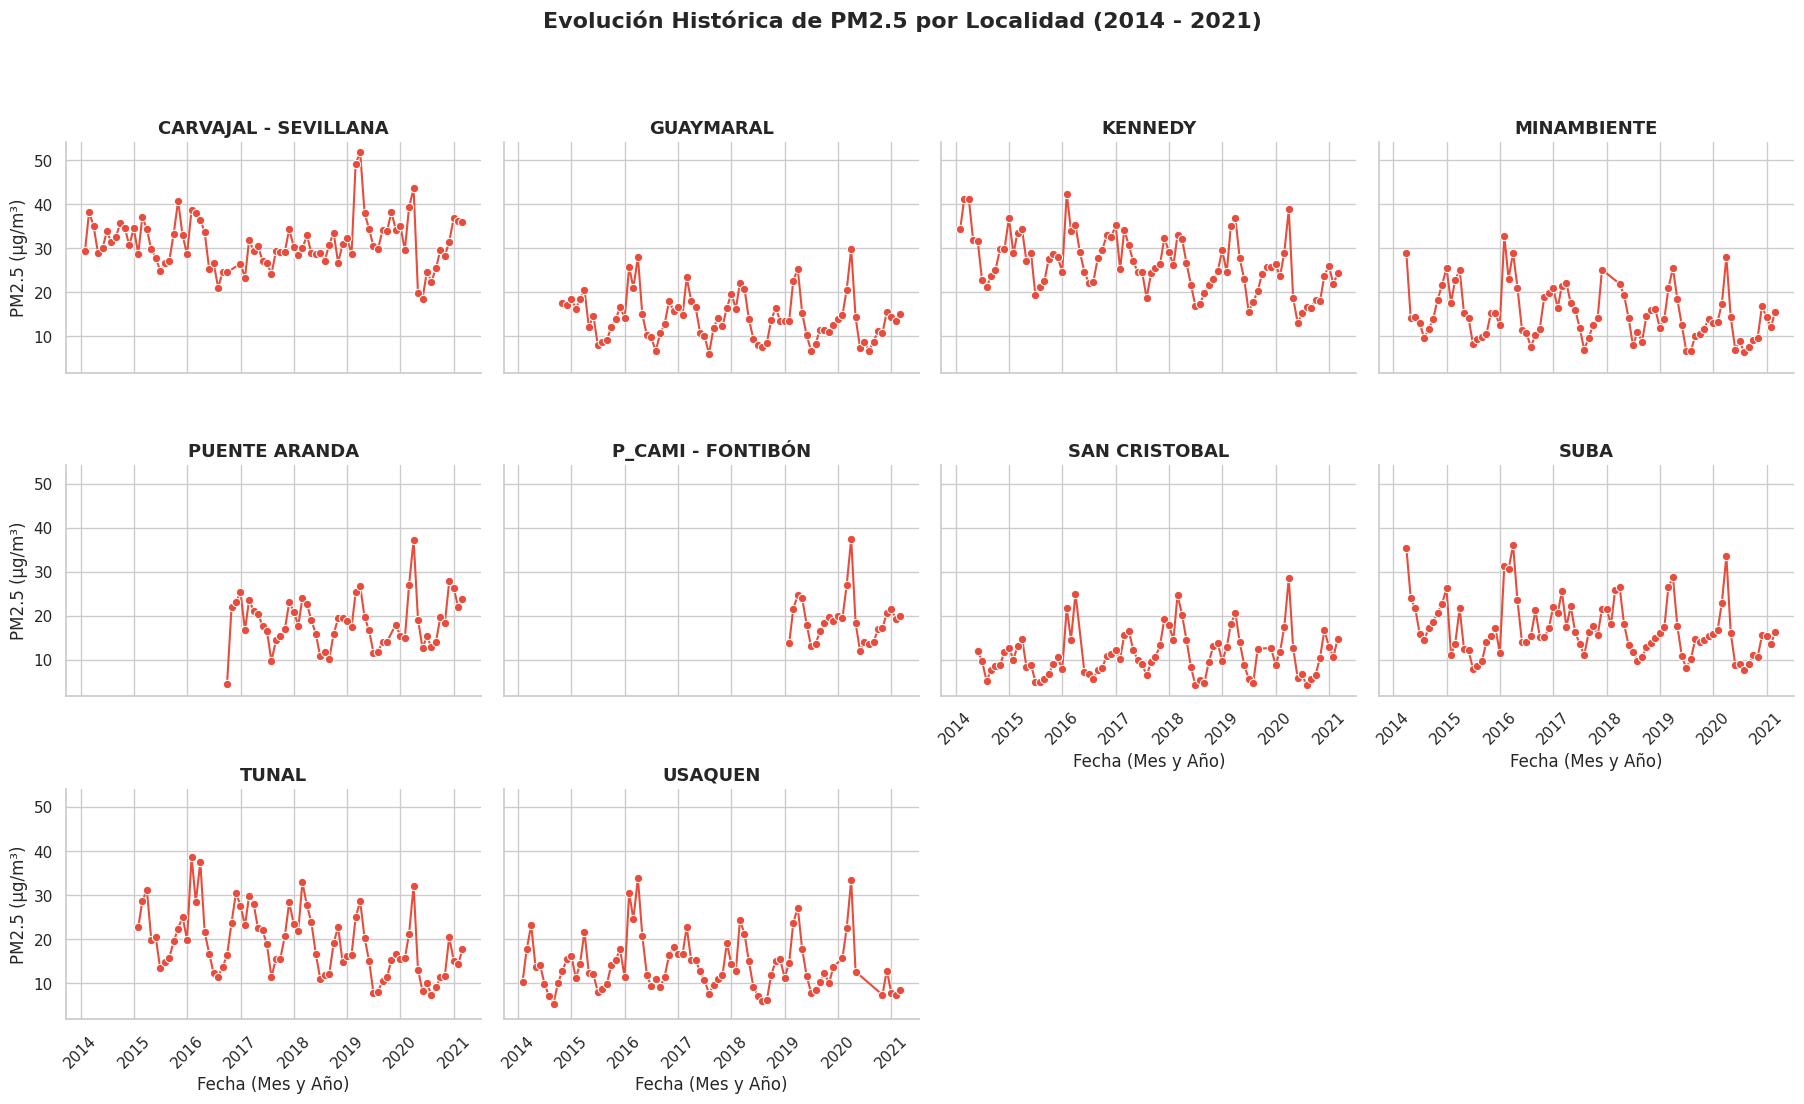

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar el estilo
sns.set_theme(style="whitegrid")

# Usamos relplot que es especial para ver relaciones en el tiempo (líneas)
g = sns.relplot(
    data=df,
    x="fecha",
    y="pm25",
    col="estacion",
    col_wrap=4,          # 4 columnas por fila
    kind="line",         # Gráfico de líneas
    marker="o",          # Pone un puntito en cada mes exacto
    height=3.5,
    aspect=1.3,
    color="#e74c3c",     # Color rojo oscuro para PM2.5
    linewidth=1.5
)

# Ajustar títulos y etiquetas
g.set_titles(col_template="{col_name}", size=13, weight='bold')
g.set_axis_labels("Fecha (Mes y Año)", "PM2.5 (µg/m³)")

# Rotar las fechas en el eje X para que no se amontonen y se puedan leer
for ax in g.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(45)

# Título principal
g.fig.suptitle('Evolución Histórica de PM2.5 por Localidad (2014 - 2021)',
               y=1.05, fontsize=16, weight='bold')

plt.tight_layout()
plt.show()

**Análisis general**

- Las series muestran una estratificación geográfica clara:
  1. Un grupo crítico al suroccidente (Carvajal–Sevillana y Kennedy), con niveles altos durante todo el periodo, asociado a actividad industrial y tráfico de carga.
  2. Un grupo intermedio (Puente Aranda, Fontibón, Tunal y Suba), con niveles moderados y picos frecuentes.
  3. Un grupo más limpio en los bordes de la ciudad (San Cristóbal, Usaquén, Guaymaral y MinAmbiente), con mejor ventilación y menos industria.
- Todas las estaciones repiten un ciclo anual: los meses más contaminados son febrero y marzo, y los más limpios, junio a agosto.
- Fontibón solo tiene datos desde 2019 y Puente Aranda desde finales de 2016, así que sus niveles cubren un periodo más corto que el resto.

**CARVAJAL - SEVILLANA**
- Presenta valores altos y bastante variables (la mayoría de los meses entre ≈25 y 38 µg/m³), con picos frecuentes. Esto indica contaminación sostenida y episodios críticos. La zona es altamente industrial y con tráfico pesado (corredores logísticos del sur), lo que genera emisiones constantes de partículas finas.

**GUAYMARAL**
- Se mantiene en niveles relativamente bajos (≈8–21 µg/m³), con oscilaciones pero sin picos extremos. Es una zona al norte, menos urbanizada y con mayor ventilación atmosférica, lo que favorece la dispersión de contaminantes.

**KENNEDY**
- Muestra niveles altos y muy variables (≈18–35 µg/m³), con varios picos. Es una de las localidades más densas y con mayor tráfico vehicular e industria, lo que explica la contaminación elevada y fluctuante.

**MINAMBIENTE**
- Tiene valores moderados (≈8–23 µg/m³), con variabilidad pero sin extremos altos. Esto sugiere una zona más regulada o con menor carga industrial directa. También puede reflejar su ubicación más institucional y con menor tráfico pesado.

**PUENTE ARANDA**
- Se observan niveles medios-altos (≈12–25 µg/m³) con tendencia creciente desde 2019 y picos importantes. Es una zona industrial histórica de la ciudad, lo que explica emisiones constantes de material particulado.

**P_CAMI - FONTIBÓN**
- Presenta valores moderados (≈14–24 µg/m³), con picos de hasta ≈37 µg/m³. Solo tiene datos desde 2019. Fontibón está influenciada por el aeropuerto y actividad logística, lo que genera emisiones de combustión y tráfico de carga.

**SAN CRISTOBAL**
- Se mantiene en niveles relativamente bajos (≈6–18 µg/m³), con algunos aumentos puntuales. Es una zona más residencial y de ladera, con mejor dispersión del aire, lo que reduce la acumulación de contaminantes.

**SUBA**
- Muestra niveles moderados (≈10–25 µg/m³) con variabilidad constante. Aunque tiene zonas residenciales, el alto tráfico y expansión urbana explican los niveles intermedios de contaminación.

**TUNAL**
- Presenta valores variables (≈11–29 µg/m³) con picos frecuentes. La mezcla de tráfico urbano y alta densidad poblacional contribuye a esta fluctuación en los niveles de PM2.5.


**USAQUÉN**
- Se mantiene en niveles moderados-bajos (≈8–23 µg/m³), con variabilidad leve. Es una zona con mejor planificación urbana y más áreas verdes, además de menor presencia industrial, lo que reduce la contaminación.

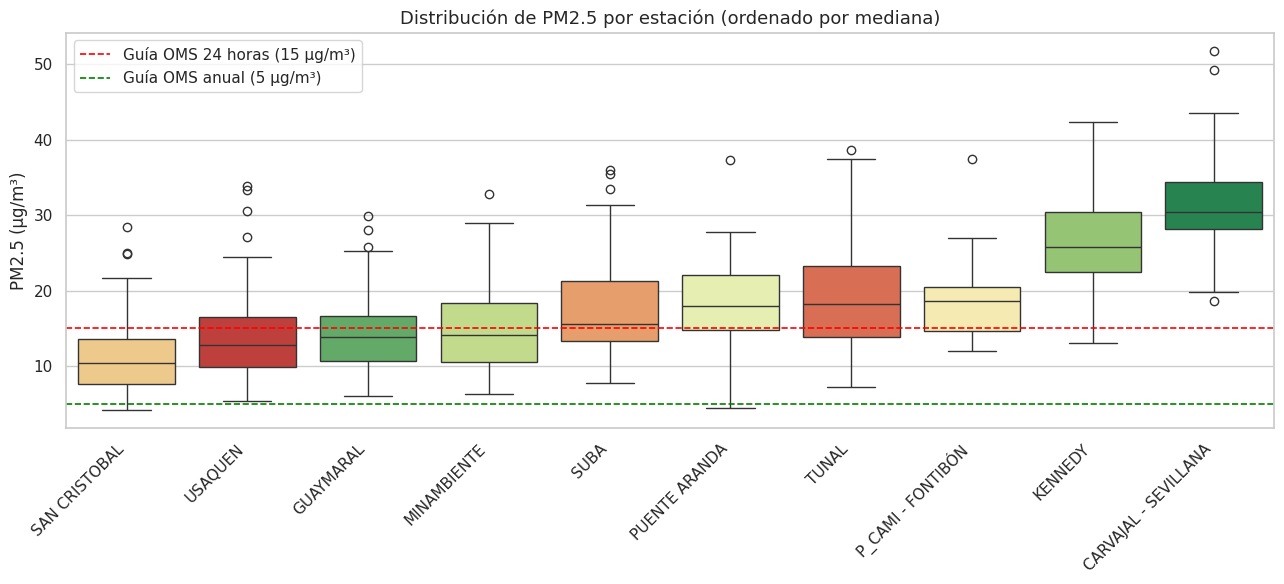

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ordenar estaciones por mediana de PM2.5 (de menor a mayor contaminación)
orden = df.groupby('estacion')['pm25'].median().sort_values().index

plt.figure(figsize=(13, 6))
sns.boxplot(data=df, x='estacion', y='pm25', order=orden, hue='estacion',
            palette='RdYlGn_r', legend=False)
plt.axhline(y=15, color='red', linestyle='--', linewidth=1.2,
            label='Guía OMS 24 horas (15 µg/m³)')
plt.axhline(y=5, color='green', linestyle='--', linewidth=1.2,
            label='Guía OMS anual (5 µg/m³)')
plt.xticks(rotation=45, ha='right')
plt.title('Distribución de PM2.5 por estación (ordenado por mediana)', fontsize=13)
plt.ylabel('PM2.5 (µg/m³)')
plt.xlabel('')
plt.legend(loc='upper left')
plt.tight_layout()
plt.show()

In [11]:
df.groupby('estacion')['pm25'].median().sort_values(ascending=False)

,pm25
estacion,
CARVAJAL - SEVILLANA,30.376526
KENNEDY,25.832046
P_CAMI - FONTIBÓN,18.640930
TUNAL,18.287366
PUENTE ARANDA,17.986806
SUBA,15.653217
MINAMBIENTE,14.095478
GUAYMARAL,13.894274
USAQUEN,12.750697


**Análisis general del boxplot**

- Hay una diferencia clara entre las zonas periféricas o residenciales y las industriales o centrales. Las medianas más altas coinciden con actividad industrial y corredores de transporte.
- La estación menos contaminada (San Cristóbal, mediana mensual de 10,4 µg/m³) y la más contaminada (Carvajal–Sevillana, 30,4 µg/m³) están en una relación de casi 3 a 1: el problema no es homogéneo sino que se concentra en el suroccidente.
- Las 10 estaciones superan la guía anual de la OMS (5 µg/m³), incluso la más limpia, que la duplica.
- En 6 de ellas (Carvajal, Kennedy, Fontibón, Tunal, Puente Aranda y Suba) la mediana mensual está por encima de 15 µg/m³, el nivel de la guía de 24 horas: un mes típico en esas zonas tiene un promedio por encima de lo que la OMS acepta para un solo día.

**SAN CRISTÓBAL**

- Presenta una mediana baja (≈10,4 µg/m³) y poca dispersión, lo que indica niveles estables y relativamente limpios. La mayoría de valores están cerca del rango bajo. Esto se explica por ser una zona de ladera, con buena ventilación y menor actividad industrial.


**USAQUÉN**

- Muestra una mediana moderada (≈12,8 µg/m³) con algunos valores atípicos más altos. Indica buena calidad del aire en general, pero con episodios puntuales de contaminación, posiblemente por tráfico en horas pico.


**MINAMBIENTE**

- Presenta mediana moderada (≈14,1 µg/m³) y dispersión amplia. Hay variabilidad importante, lo que indica que aunque normalmente está en niveles medios, puede tener picos ocasionales. Esto puede deberse a variaciones en condiciones atmosféricas más que a fuentes directas.

**GUAYMARAL**

- Tiene mediana moderada (≈13,9 µg/m³) con dispersión media. Indica niveles relativamente controlados pero con fluctuaciones. La zona abierta favorece dispersión, pero factores climáticos pueden generar variabilidad.

**SUBA**

- Muestra mediana más alta (≈15,7 µg/m³) y dispersión amplia. Indica contaminación más frecuente y variable. Esto se explica por alta densidad poblacional y tráfico intenso.

**TUNAL**

- Presenta mediana relativamente alta (≈18,3 µg/m³) y gran variabilidad. Hay muchos valores altos, lo que indica episodios frecuentes de contaminación. Es una zona urbana con tráfico y alta actividad.

**PUENTE ARANDA**

- Tiene mediana alta (≈18,0 µg/m³) y amplia dispersión, con valores extremos. Esto refleja contaminación constante con episodios severos. La fuerte actividad industrial explica este comportamiento.

**P. CAMI - FONTIBÓN**

- Mediana alta (≈18,6 µg/m³) y variabilidad moderada, calculada solo sobre 2019–2021. Indica contaminación sostenida. La cercanía al aeropuerto y logística de carga aporta emisiones constantes.

**KENNEDY**

- Presenta mediana alta (≈25,8 µg/m³) y alta dispersión. Es una de las localidades más contaminadas, con muchos episodios críticos. Se explica por densidad poblacional, tráfico pesado e industria.

**CARVAJAL - SEVILLANA**

- Es la más crítica: mediana muy alta (≈30,4 µg/m³) y valores extremos elevados. Indica contaminación persistente y severa. Es una zona industrial clave con alta carga vehicular, lo que genera acumulación constante de PM2.5.

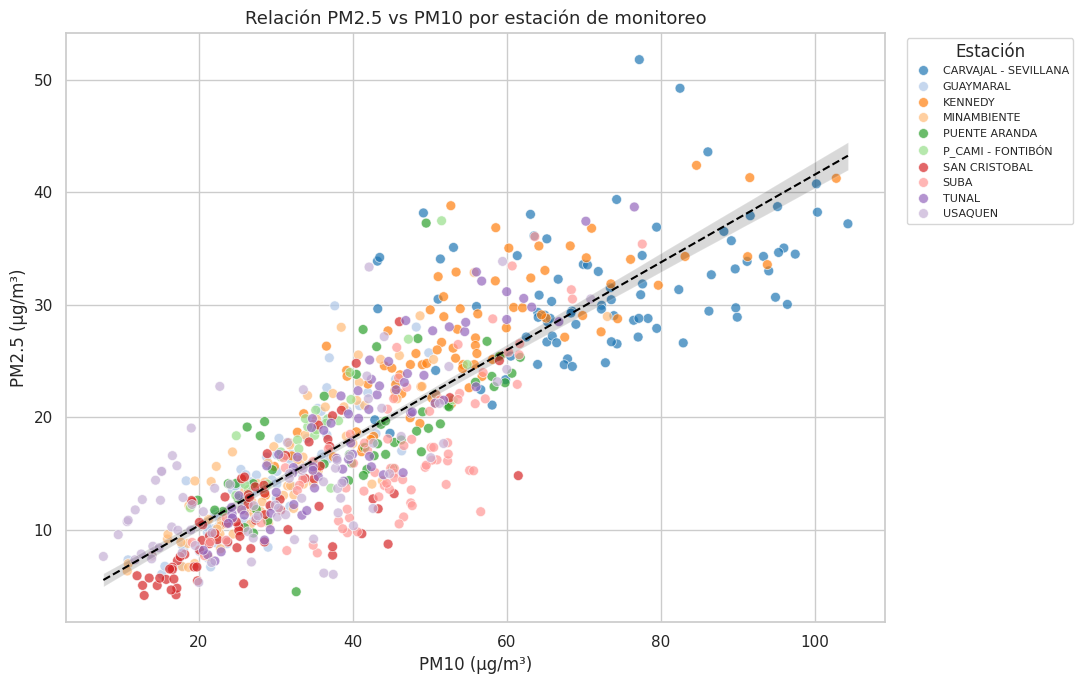

In [12]:
plt.figure(figsize=(11, 7))
sns.scatterplot(data=df, x='pm10', y='pm25', hue='estacion',
                alpha=0.7, s=50, palette='tab20')
# Línea de regresión global
sns.regplot(data=df, x='pm10', y='pm25', scatter=False,
            color='black', line_kws={'linestyle':'--', 'linewidth': 1.5})

plt.title('Relación PM2.5 vs PM10 por estación de monitoreo', fontsize=13)
plt.xlabel('PM10 (µg/m³)')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8, title='Estación')
plt.tight_layout()
plt.show()

In [13]:
promedios = df.groupby('estacion')[['pm25', 'pm10']].mean()
ratio_finas = (promedios['pm25'] / promedios['pm10']).sort_values(ascending=False)
print(f"Correlación PM2.5–PM10 (promedios mensuales): r = {df['pm25'].corr(df['pm10']):.2f}\n")
print("Proporción PM2.5/PM10 por estación:")
print(ratio_finas.round(2))

Correlación PM2.5–PM10 (promedios mensuales): r = 0.86

Proporción PM2.5/PM10 por estación:
estacion
P_CAMI - FONTIBÓN       0.54
GUAYMARAL               0.49
MINAMBIENTE             0.49
KENNEDY                 0.48
USAQUEN                 0.48
TUNAL                   0.47
PUENTE ARANDA           0.45
CARVAJAL - SEVILLANA    0.43
SAN CRISTOBAL           0.41
SUBA                    0.37
dtype: float64


In [14]:
df.groupby('estacion').size().sort_values()

,0
estacion,
P_CAMI - FONTIBÓN,26
PUENTE ARANDA,53
TUNAL,74
GUAYMARAL,77
SAN CRISTOBAL,79
USAQUEN,80
MINAMBIENTE,81
CARVAJAL - SEVILLANA,84
SUBA,84


**Análisis**

- La correlación entre PM2.5 y PM10 es positiva y fuerte (r = 0,86 en promedios mensuales): cuando sube el PM10 casi siempre sube el PM2.5. Ambos comparten fuentes, principalmente combustión (vehículos, industria) y material resuspendido.
- La proporción entre ambos cambia por estación. Fontibón tiene la mayor fracción de partículas finas (0,54), típicas de combustión, coherente con la actividad aeroportuaria; Suba (0,37) y San Cristóbal (0,41) tienen la menor, con más peso de partículas gruesas (polvo, vías, construcción).
- Las estaciones más contaminadas no son las de mayor fracción fina: Carvajal–Sevillana está entre las más bajas (0,43) y Kennedy en un valor intermedio (0,48). Su problema es la cantidad total de partículas, finas y gruesas a la vez, más que la composición.

Meses con datos por año: {2014: 12, 2015: 12, 2016: 12, 2017: 12, 2018: 12, 2019: 12, 2020: 12, 2021: 2}


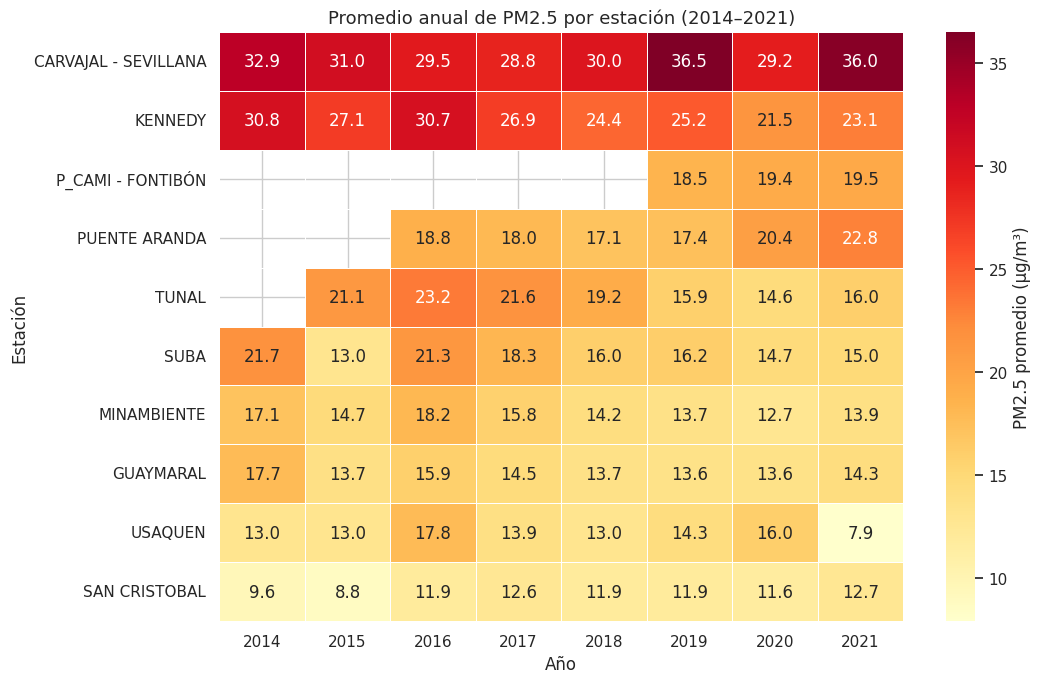

In [15]:
df_heat = df.copy()
df_heat['año'] = df_heat['fecha'].dt.year

pivot = df_heat.pivot_table(index='estacion', columns='año',
                             values='pm25', aggfunc='mean')
# Ordenar estaciones de mayor a menor contaminación promedio
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]

# Cobertura: 2021 solo tiene datos de enero y febrero
print('Meses con datos por año:', df_heat.groupby('año')['fecha'].apply(lambda s: s.dt.month.nunique()).to_dict())

plt.figure(figsize=(11, 7))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd',
            cbar_kws={'label': 'PM2.5 promedio (µg/m³)'},
            linewidths=0.5)
plt.title('Promedio anual de PM2.5 por estación (2014–2021)', fontsize=13)
plt.xlabel('Año')
plt.ylabel('Estación')
plt.tight_layout()
plt.show()

**Análisis**

- Entre 2014 y 2020 varias estaciones bajan de forma sostenida: Kennedy pasa de 30,8 a 21,5 µg/m³, Tunal de 21,1 a 14,6 y MinAmbiente de 17,1 a 12,7. Carvajal–Sevillana no mejora: se mantiene alrededor de 30 µg/m³, con 36,5 en 2019.
- El efecto de 2020 es mixto: frente a 2019 bajan Carvajal y Kennedy, pero suben Puente Aranda, Usaquén y Fontibón. En el agregado, la caída es pequeña.
- La columna de 2021 no es comparable: solo incluye enero y febrero, meses que están entre los más contaminados del año. Los valores altos de 2021 reflejan esa estacionalidad, no un repunte por la reactivación.
- San Cristóbal y Guaymaral se mantienen bajos y estables en todo el periodo.

## Análisis final de la exploración

- La contaminación por PM2.5 en Bogotá es desigual en el espacio y persistente en el tiempo. Las diferencias entre estaciones (de 10,4 a 30,4 µg/m³ de mediana mensual) son mucho mayores que los cambios de un año a otro.
- Carvajal–Sevillana y Kennedy concentran los niveles más altos y la mayor variabilidad. San Cristóbal y Usaquén son las más limpias y estables. Las 10 estaciones superan la guía anual de la OMS (5 µg/m³) y 6 tienen medianas mensuales por encima de 15 µg/m³.
- Hay una tendencia a la baja en varias estaciones entre 2014 y 2020, pero no en la más contaminada. El efecto de la pandemia en 2020 es mixto, y 2021 no permite sacar conclusiones porque solo tiene dos meses de datos.
- PM2.5 y PM10 están fuertemente correlacionados (r = 0,86). La fracción fina varía entre 0,37 (Suba) y 0,54 (Fontibón), y las zonas críticas no son las de mayor fracción fina: combinan partículas finas y gruesas en grandes cantidades.
- En conjunto, el problema requiere medidas diferenciadas por zona: reducir emisiones de combustión (flota diésel, industria) donde la carga total es alta y controlar el polvo y la resuspensión donde predominan las partículas gruesas.

## CLUSTERING

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# Limpieza preventiva de comillas en los nombres de estación
df_final['estacion'] = df_final['estacion'].str.replace('"', '').str.strip()

# Construcción de features por estación
df_features = df_final.groupby('estacion').agg(
    pm25_mean=('pm25', 'mean'),
    pm25_std=('pm25', 'std'),
    pm25_max=('pm25', 'max'),
    pm25_p90=('pm25', lambda x: x.quantile(0.90)),
    pm10_mean=('pm10', 'mean'),
    pm10_std=('pm10', 'std'),
).reset_index()

# Ratio PM2.5/PM10 (composición del material particulado)
df_features['ratio_finas'] = df_features['pm25_mean'] / df_features['pm10_mean']

# Excluir estaciones con datos insuficientes (menos de 24 registros)
conteos = df_final.groupby('estacion').size()
estaciones_validas = conteos[conteos >= 24].index
df_features = df_features[df_features['estacion'].isin(estaciones_validas)].reset_index(drop=True)

print("Estaciones incluidas en el clustering:", len(df_features))
print("\nFeatures construidas:")
print(df_features.round(2))

Estaciones incluidas en el clustering: 10

Features construidas:
               estacion  pm25_mean  pm25_std  pm25_max  pm25_p90  pm10_mean  \
0  CARVAJAL - SEVILLANA      31.31      9.81     81.12     43.66      72.54   
1             GUAYMARAL      14.32      7.69     53.38     25.04      28.82   
2               KENNEDY      26.43      9.95     70.20     40.13      54.71   
3           MINAMBIENTE      14.87      9.26     68.67     28.44      30.15   
4         PUENTE ARANDA      18.73      8.59     60.75     30.11      41.32   
5     P_CAMI - FONTIBÓN      19.07      8.13     60.94     29.73      35.29   
6         SAN CRISTOBAL      11.22      7.23     54.89     21.40      27.19   
7                  SUBA      16.98      8.67     58.29     29.02      45.20   
8                 TUNAL      19.09     10.79     61.36     34.97      40.60   
9               USAQUEN      14.30      8.96     58.70     27.08      30.12   

   pm10_std  ratio_finas  
0     25.06         0.43  
1     12.45

In [17]:
features_cols = ['pm25_mean', 'pm25_std', 'pm25_max', 'pm25_p90',
                 'pm10_mean', 'pm10_std', 'ratio_finas']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_features[features_cols])

print("Datos escalados (media≈0, std≈1):")
print(pd.DataFrame(X_scaled, columns=features_cols).describe().round(2))

Datos escalados (media≈0, std≈1):
       pm25_mean  pm25_std  pm25_max  pm25_p90  pm10_mean  pm10_std  \
count      10.00     10.00     10.00     10.00      10.00     10.00   
mean        0.00     -0.00      0.00      0.00       0.00     -0.00   
std         1.05      1.05      1.05      1.05       1.05      1.05   
min        -1.29     -1.63     -1.20     -1.48      -1.00     -1.42   
25%        -0.73     -0.65     -0.56     -0.55      -0.78     -0.69   
50%        -0.13     -0.09     -0.25     -0.25      -0.20     -0.24   
75%         0.08      0.74      0.51      0.43       0.27      0.39   
max         2.20      1.82      2.32      1.97       2.38      2.20   

       ratio_finas  
count        10.00  
mean          0.00  
std           1.05  
min          -1.96  
25%          -0.59  
50%           0.21  
75%           0.62  
max           1.73  


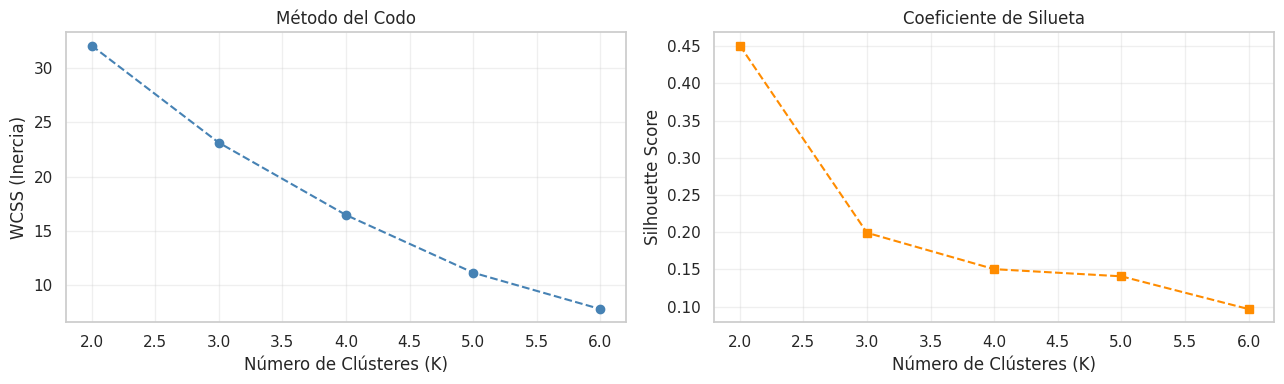


Silueta por K:
  K=2: 0.451
  K=3: 0.199
  K=4: 0.150
  K=5: 0.141
  K=6: 0.097


In [18]:
# Método del codo y silueta para encontrar K óptimo
wcss = []
silhouettes = []
K_range = range(2, 7)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    wcss.append(kmeans.inertia_)
    silhouettes.append(silhouette_score(X_scaled, labels))

# Visualización dual
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(K_range, wcss, marker='o', linestyle='--', color='steelblue')
axes[0].set_title('Método del Codo')
axes[0].set_xlabel('Número de Clústeres (K)')
axes[0].set_ylabel('WCSS (Inercia)')
axes[0].grid(True, alpha=0.3)

axes[1].plot(K_range, silhouettes, marker='s', linestyle='--', color='darkorange')
axes[1].set_title('Coeficiente de Silueta')
axes[1].set_xlabel('Número de Clústeres (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nSilueta por K:")
for k, s in zip(K_range, silhouettes):
    print(f"  K={k}: {s:.3f}")

**Selección del número de grupos**

- Se usaron el método del codo (inercia) y el coeficiente de silueta.
- La silueta es máxima con K = 2 (0,451), pero esa partición solo separa a Carvajal–Sevillana y Kennedy del resto de estaciones, algo que ya se veía en el análisis exploratorio.
- Se eligió K = 3 para obtener una segmentación más informativa, a costa de una silueta más baja (0,199). Ese valor indica que la estructura de grupos es débil: con 10 estaciones, los niveles de contaminación cambian de forma gradual más que en grupos bien separados.

In [19]:
K_OPTIMO = 3  # Ajusta según lo que veas en las gráficas anteriores

kmeans_final = KMeans(n_clusters=K_OPTIMO, init='k-means++', random_state=42, n_init=10)
df_features['cluster_kmeans'] = kmeans_final.fit_predict(X_scaled)

print("Asignación K-Means:")
print(df_features[['estacion', 'pm25_mean', 'cluster_kmeans']].sort_values('cluster_kmeans'))

Asignación K-Means:
               estacion  pm25_mean  cluster_kmeans
1             GUAYMARAL  14.320192               0
5     P_CAMI - FONTIBÓN  19.066972               0
6         SAN CRISTOBAL  11.216259               0
0  CARVAJAL - SEVILLANA  31.305694               1
2               KENNEDY  26.433254               1
3           MINAMBIENTE  14.868212               2
4         PUENTE ARANDA  18.727824               2
7                  SUBA  16.984299               2
8                 TUNAL  19.093318               2
9               USAQUEN  14.295972               2


**Grupos con K-Means (K = 3)**

- **Cluster 1, crítico:** Carvajal–Sevillana y Kennedy. Son las dos estaciones con los niveles más altos de PM2.5 y PM10, asociadas a tráfico de carga, industria y alta densidad urbana.
- **Cluster 2, intermedio y variable:** MinAmbiente, Puente Aranda, Suba, Tunal y Usaquén. Tienen niveles moderados (14–19 µg/m³ de promedio) con más variabilidad y picos más altos que el cluster 0.
- **Cluster 0, bajo y estable:** Guaymaral, Fontibón y San Cristóbal. Tienen la menor variabilidad del conjunto. Fontibón entra aquí pese a su promedio de 19 µg/m³ porque sus picos y su PM10 son bajos y su fracción de partículas finas es alta; además, solo tiene datos desde 2019.

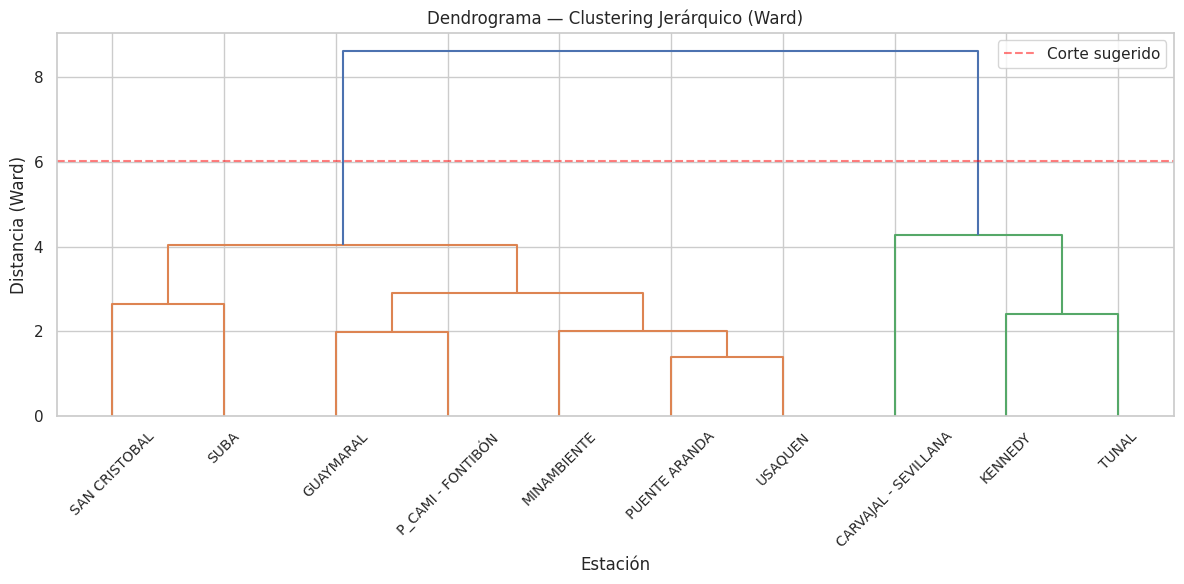

Asignación Jerárquico:
               estacion  pm25_mean  cluster_jerarquico
1             GUAYMARAL  14.320192                   0
3           MINAMBIENTE  14.868212                   0
5     P_CAMI - FONTIBÓN  19.066972                   0
4         PUENTE ARANDA  18.727824                   0
6         SAN CRISTOBAL  11.216259                   0
7                  SUBA  16.984299                   0
9               USAQUEN  14.295972                   0
2               KENNEDY  26.433254                   1
8                 TUNAL  19.093318                   1
0  CARVAJAL - SEVILLANA  31.305694                   2


In [20]:
# Linkage matrix (método de Ward, óptimo para clusters compactos)
Z = linkage(X_scaled, method='ward')

# Dendrograma
plt.figure(figsize=(12, 6))
dendrogram(Z, labels=df_features['estacion'].values, leaf_rotation=45,
           leaf_font_size=10, color_threshold=0.7*max(Z[:,2]))
plt.title('Dendrograma — Clustering Jerárquico (Ward)')
plt.xlabel('Estación')
plt.ylabel('Distancia (Ward)')
plt.axhline(y=0.7*max(Z[:,2]), color='red', linestyle='--', alpha=0.5,
            label='Corte sugerido')
plt.legend()
plt.tight_layout()
plt.show()

# Aplicar clustering jerárquico con el mismo K
hier = AgglomerativeClustering(n_clusters=K_OPTIMO, linkage='ward')
df_features['cluster_jerarquico'] = hier.fit_predict(X_scaled)

print("Asignación Jerárquico:")
print(df_features[['estacion', 'pm25_mean', 'cluster_jerarquico']].sort_values('cluster_jerarquico'))

**Análisis**

- El dendrograma (método de Ward) separa primero a Carvajal–Sevillana del resto: es la estación con el perfil más extremo y forma un grupo propio.
- El segundo grupo reúne a Kennedy y Tunal, con niveles altos y la mayor variabilidad después de Carvajal.
- Las otras siete estaciones (Guaymaral, MinAmbiente, Puente Aranda, Fontibón, San Cristóbal, Suba y Usaquén) forman un grupo amplio de contaminación baja a moderada.
- Frente a K-Means, el jerárquico aísla a Carvajal en vez de unirla con Kennedy, y lleva a Tunal al grupo alto.

In [21]:
# Coeficientes de silueta para comparar
sil_kmeans = silhouette_score(X_scaled, df_features['cluster_kmeans'])
sil_hier = silhouette_score(X_scaled, df_features['cluster_jerarquico'])

print(f"Silhouette Score:")
print(f"  K-Means:     {sil_kmeans:.3f}")
print(f"  Jerárquico:  {sil_hier:.3f}")

# Tabla comparativa de asignaciones
comparacion = df_features[['estacion', 'pm25_mean', 'cluster_kmeans', 'cluster_jerarquico']]
print("\nComparación de asignaciones:")
print(comparacion.sort_values('pm25_mean', ascending=False))

Silhouette Score:
  K-Means:     0.199
  Jerárquico:  0.255

Comparación de asignaciones:
               estacion  pm25_mean  cluster_kmeans  cluster_jerarquico
0  CARVAJAL - SEVILLANA  31.305694               1                   2
2               KENNEDY  26.433254               1                   1
8                 TUNAL  19.093318               2                   1
5     P_CAMI - FONTIBÓN  19.066972               0                   0
4         PUENTE ARANDA  18.727824               2                   0
7                  SUBA  16.984299               2                   0
3           MINAMBIENTE  14.868212               2                   0
1             GUAYMARAL  14.320192               0                   0
9               USAQUEN  14.295972               2                   0
6         SAN CRISTOBAL  11.216259               0                   0


**Análisis**

- El clustering jerárquico obtiene una silueta mayor (0,255) que K-Means (0,199), así que se toma como modelo final. Ambos valores son bajos: las fronteras entre grupos son difusas, lo esperable cuando la contaminación cambia de forma gradual entre zonas.
- Los dos métodos coinciden en lo principal: Carvajal–Sevillana y Kennedy son las estaciones críticas, y San Cristóbal, Guaymaral y Fontibón quedan siempre en el grupo de menor contaminación.
- Las diferencias están en las estaciones intermedias. Tunal pasa del grupo intermedio (K-Means) al alto (jerárquico), y MinAmbiente, Puente Aranda, Suba y Usaquén pasan del intermedio al grupo amplio. Son estaciones de transición entre perfiles.

Varianza explicada por PC1: 72.6%
Varianza explicada por PC2: 15.9%
Varianza acumulada: 88.4%


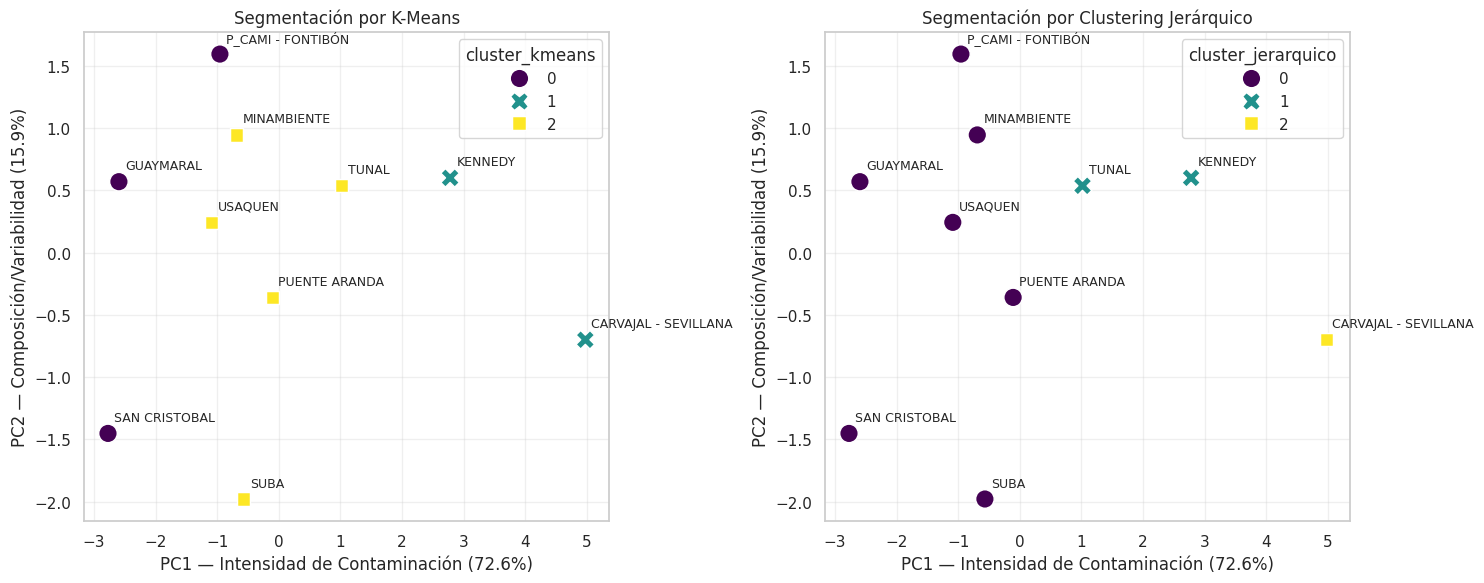

In [22]:
# Reducción a 2 componentes para visualizar
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
df_features['pca1'] = X_pca[:, 0]
df_features['pca2'] = X_pca[:, 1]

print(f"Varianza explicada por PC1: {pca.explained_variance_ratio_[0]*100:.1f}%")
print(f"Varianza explicada por PC2: {pca.explained_variance_ratio_[1]*100:.1f}%")
print(f"Varianza acumulada: {sum(pca.explained_variance_ratio_)*100:.1f}%")

# Visualización lado a lado
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, col, titulo in zip(axes,
                            ['cluster_kmeans', 'cluster_jerarquico'],
                            ['K-Means', 'Clustering Jerárquico']):
    sns.scatterplot(data=df_features, x='pca1', y='pca2', hue=col,
                    style=col, s=180, palette='viridis', ax=ax, legend='full')
    for i in range(df_features.shape[0]):
        ax.annotate(df_features['estacion'].iloc[i],
                    (df_features['pca1'].iloc[i]+0.1, df_features['pca2'].iloc[i]+0.1),
                    fontsize=9)
    ax.set_title(f'Segmentación por {titulo}', fontsize=12)
    ax.set_xlabel(f'PC1 — Intensidad de Contaminación ({pca.explained_variance_ratio_[0]*100:.1f}%)')
    ax.set_ylabel(f'PC2 — Composición/Variabilidad ({pca.explained_variance_ratio_[1]*100:.1f}%)')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

**Análisis**

- Las dos primeras componentes explican el 88,4 % de la varianza (72,6 % y 15,9 %), así que el plano conserva casi toda la información de las siete variables.
- PC1 resume la intensidad general de contaminación: todas las variables de nivel y variabilidad pesan casi igual. Carvajal–Sevillana queda en un extremo, seguida de Kennedy y Tunal; San Cristóbal y Guaymaral, en el opuesto.
- PC2 es casi únicamente la fracción de partículas finas (PM2.5/PM10). Fontibón queda en un extremo (la mayor fracción fina) y Suba y San Cristóbal en el otro (la menor).
- Los grupos se separan sobre todo a lo largo de PC1: la calidad del aire en estas estaciones es ante todo un gradiente de intensidad, con diferencias secundarias de composición.

Perfil promedio de cada cluster:
                    pm25_mean  pm25_std  pm25_max  pm25_p90  pm10_mean  \
cluster_jerarquico                                                       
0                       15.64      8.36     59.37     27.26      34.01   
1                       22.76     10.37     65.78     37.55      47.65   
2                       31.31      9.81     81.12     43.66      72.54   

                    pm10_std  ratio_finas  
cluster_jerarquico                         
0                      15.57         0.46  
1                      19.97         0.48  
2                      25.06         0.43  


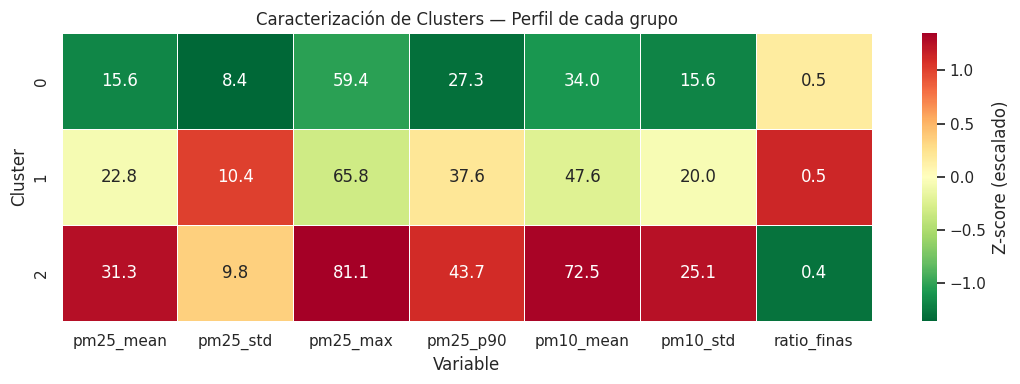


Estaciones por cluster:

Cluster 0: ['GUAYMARAL', 'MINAMBIENTE', 'PUENTE ARANDA', 'P_CAMI - FONTIBÓN', 'SAN CRISTOBAL', 'SUBA', 'USAQUEN']

Cluster 1: ['KENNEDY', 'TUNAL']

Cluster 2: ['CARVAJAL - SEVILLANA']


In [23]:
MODELO_GANADOR = 'cluster_jerarquico'  # mayor silueta

# Perfil promedio de cada cluster
perfil = df_features.groupby(MODELO_GANADOR)[features_cols].mean().round(2)
print("Perfil promedio de cada cluster:")
print(perfil)

# Heatmap de caracterización (escalado para que sea comparable)
perfil_escalado = pd.DataFrame(
    StandardScaler().fit_transform(perfil),
    columns=perfil.columns,
    index=perfil.index
)

plt.figure(figsize=(11, 4))
sns.heatmap(perfil_escalado, annot=perfil.round(1), fmt='', cmap='RdYlGn_r',
            cbar_kws={'label': 'Z-score (escalado)'}, linewidths=0.5)
plt.title('Caracterización de Clusters — Perfil de cada grupo')
plt.ylabel('Cluster')
plt.xlabel('Variable')
plt.tight_layout()
plt.show()

# Listar estaciones por cluster
print("\nEstaciones por cluster:")
for cluster_id in sorted(df_features[MODELO_GANADOR].unique()):
    estaciones = df_features[df_features[MODELO_GANADOR] == cluster_id]['estacion'].tolist()
    print(f"\nCluster {cluster_id}: {estaciones}")

**Análisis**

Perfil de los grupos del modelo final (jerárquico):

- **Cluster 2, Carvajal–Sevillana:** los valores más altos en todas las métricas: promedio de PM2.5 de 31,3 µg/m³, máximo de 81 µg/m³ y PM10 de 72,5 µg/m³. Tiene la menor fracción fina de los tres grupos (0,43): su carga es alta tanto en partículas finas como gruesas.
- **Cluster 1, Kennedy y Tunal:** nivel alto (22,8 µg/m³) y la mayor variabilidad relativa, con percentil 90 de 37,6 µg/m³.
- **Cluster 0, las otras siete estaciones:** el nivel más bajo (15,6 µg/m³) y la menor variabilidad. Es un grupo amplio que incluye desde San Cristóbal (11,2 µg/m³) hasta Fontibón (19,1 µg/m³).
- La fracción fina casi no cambia entre grupos (0,43–0,48): lo que los distingue es la intensidad, no la composición.

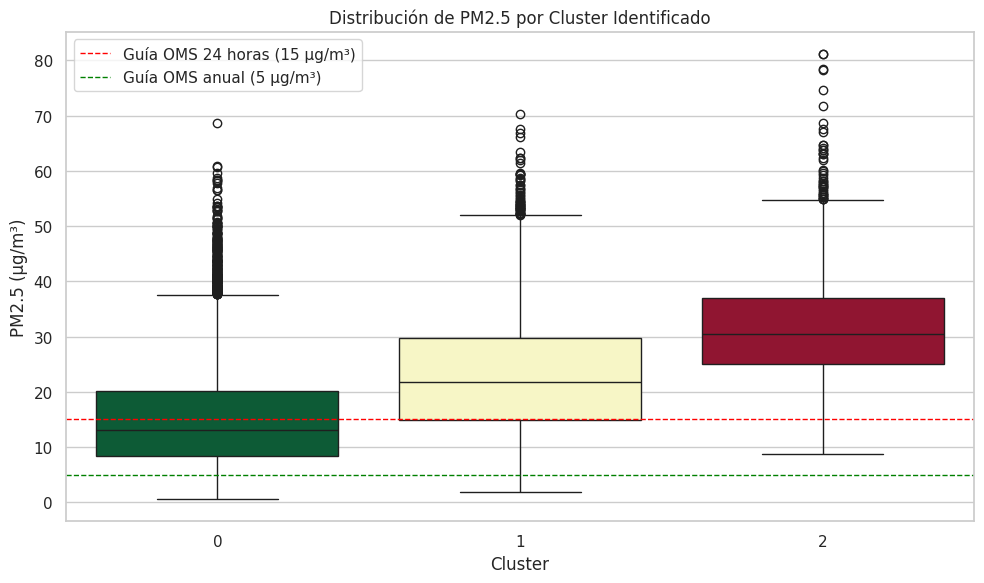

In [24]:
# Mapear cada estación con su cluster en el dataset original
df_con_cluster = df_final.merge(
    df_features[['estacion', MODELO_GANADOR]],
    on='estacion', how='inner'
)

plt.figure(figsize=(10, 6))
sns.boxplot(data=df_con_cluster, x=MODELO_GANADOR, y='pm25', hue=MODELO_GANADOR,
            palette='RdYlGn_r', legend=False)
plt.axhline(y=15, color='red', linestyle='--', linewidth=1, label='Guía OMS 24 horas (15 µg/m³)')
plt.axhline(y=5, color='green', linestyle='--', linewidth=1, label='Guía OMS anual (5 µg/m³)')
plt.title('Distribución de PM2.5 por Cluster Identificado')
plt.xlabel('Cluster')
plt.ylabel('PM2.5 (µg/m³)')
plt.legend()
plt.tight_layout()
plt.show()

**Análisis**

- El boxplot usa los promedios diarios, así que la referencia directa es la guía OMS de 24 horas (15 µg/m³).
- Carvajal–Sevillana (cluster 2) tiene casi toda su distribución por encima de 15 µg/m³. Kennedy y Tunal (cluster 1) la superan en la mayor parte de los días. El cluster 0 se reparte alrededor de la guía, con días por encima en todas sus estaciones.
- Ningún grupo se acerca a la guía anual (5 µg/m³).
- Los tres grupos tienen días atípicos por encima de 40 µg/m³: incluso las zonas más limpias viven episodios de mala calidad del aire.

## Conclusiones del Proyecto
### Conclusión general

El análisis de la calidad del aire en Bogotá entre 2014 y 2021, basado en datos de PM2.5 y PM10 de 10 estaciones de monitoreo, permite concluir que la contaminación atmosférica en la ciudad es un fenómeno espacialmente desigual, temporalmente persistente y heterogéneo en intensidad y composición. Los resultados obtenidos mediante análisis exploratorio y modelos de agrupamiento muestran que la calidad del aire no se distribuye de forma homogénea en la ciudad, sino que responde a dinámicas diferenciadas asociadas a factores como actividad industrial, densidad urbana, tráfico vehicular y condiciones geográficas locales. Esta diversidad de perfiles evidencia la necesidad de estrategias específicas de intervención según las características de cada zona.

### Sobre los patrones espaciales

El análisis exploratorio reveló una clara estratificación geográfica de la contaminación. Las estaciones del suroccidente industrial, especialmente Carvajal–Sevillana y Kennedy, presentan los niveles más altos y persistentes de PM2.5, con concentraciones que superan ampliamente la guía de la OMS y con presencia frecuente de episodios extremos de contaminación. Por otro lado, estaciones como San Cristóbal, Guaymaral, MinAmbiente y Usaquén mantienen niveles relativamente bajos y más estables, favorecidas probablemente por una menor actividad industrial y mejores condiciones de dispersión atmosférica.

Las estaciones intermedias (Puente Aranda, Fontibón, Tunal y Suba) presentan niveles moderados y una mayor variabilidad temporal. Las 10 estaciones superan la guía anual de la OMS (5 µg/m³) y 6 tienen medianas mensuales por encima de 15 µg/m³, el nivel de la guía de 24 horas: la contaminación atmosférica es un problema de salud pública en toda la ciudad, no solo en el suroccidente.

### Sobre los patrones temporales

Varias estaciones muestran una tendencia a la baja entre 2014 y 2020 (Kennedy, Tunal, MinAmbiente), pero la más contaminada, Carvajal–Sevillana, no mejora. El efecto de 2020 es mixto: algunas estaciones bajan frente a 2019 y otras suben, y Carvajal y Kennedy siguen muy por encima del resto aun con las restricciones de movilidad, lo que apunta a fuentes estructurales. Los datos de 2021 solo cubren enero y febrero, así que no permiten evaluar la reactivación.

Hay además un ciclo anual marcado en todas las estaciones: febrero y marzo son los meses más contaminados y junio a agosto los más limpios.

### Sobre la relación entre PM2.5 y PM10

El análisis de correlación mostró una relación fuerte y positiva entre PM2.5 y PM10, indicando que ambos contaminantes comparten en gran medida fuentes comunes de emisión y presentan comportamientos similares en la mayoría de estaciones.

No obstante, el análisis del ratio PM2.5/PM10 permitió identificar diferencias importantes en la composición del material particulado entre clusters. Aunque las zonas más contaminadas presentan altas concentraciones absolutas de partículas, no necesariamente poseen la mayor proporción de partículas finas. De hecho, Carvajal–Sevillana, la estación más contaminada, está entre las de menor fracción fina (0,43), mientras que Fontibón tiene la mayor (0,54). Esto sugiere diferencias en las fuentes dominantes de contaminación, como combustión, tráfico pesado, resuspensión de polvo o actividades industriales.

Esta distinción entre intensidad y composición resulta relevante porque implica que las estrategias de mitigación no deben enfocarse únicamente en reducir concentraciones totales, sino también en controlar los tipos específicos de partículas predominantes en cada zona.

### Sobre el agrupamiento de estaciones

K-Means y el clustering jerárquico coinciden en lo principal: Carvajal–Sevillana y Kennedy son las estaciones críticas, y San Cristóbal, Guaymaral y Fontibón las de menor contaminación. El jerárquico obtuvo la mayor silueta (0,255 frente a 0,199) y es el modelo final:

- Cluster crítico: Carvajal–Sevillana, sola, con los valores más altos en todas las métricas.
- Cluster alto: Kennedy y Tunal, con niveles altos y la mayor variabilidad relativa.
- Cluster de baja a moderada contaminación: las otras siete estaciones.

Las siluetas son bajas: la estructura de grupos es débil y la contaminación cambia de forma gradual entre estaciones. La PCA lo confirma: la primera componente (72,6 % de la varianza) resume la intensidad de contaminación y la segunda (15,9 %) casi solo la fracción de partículas finas; los grupos se ordenan sobre todo a lo largo de la primera.

### Sobre las limitaciones del estudio

Es importante reconocer algunas limitaciones metodológicas del análisis:

- Número reducido de estaciones: trabajar con únicamente 10 estaciones limita la robustez estadística de los modelos de agrupamiento y la generalización de los resultados.
- Granularidad temporal: el análisis exploratorio usa promedios mensuales, lo que puede ocultar dinámicas diarias u horarias relevantes para comprender episodios agudos de contaminación.
- Cobertura desigual: Fontibón solo tiene datos desde 2019, Puente Aranda desde finales de 2016 y 2021 solo enero y febrero, lo que limita las comparaciones entre estaciones y años.
- Variables no consideradas: no se incluyeron variables meteorológicas como viento, precipitación o temperatura, ni información socioeconómica o de emisiones específicas por fuente.
- Dependencia de variables agregadas: los clusters se construyeron a partir de métricas resumidas, por lo que pueden perderse detalles específicos de comportamiento temporal fino.

Aun así, el análisis exploratorio, los dos métodos de agrupamiento y la PCA coinciden en lo principal: la contaminación se concentra en el suroccidente y la diferencia entre estaciones es grande.

### Implicaciones de política pública

Los resultados sugieren que una estrategia uniforme de gestión de calidad del aire no sería suficiente para Bogotá, ya que las dinámicas de contaminación varían considerablemente entre zonas.

- En zonas críticas como Carvajal–Sevillana y Kennedy, se requieren medidas estructurales orientadas a controlar emisiones industriales y tráfico pesado, incluyendo renovación de flota diésel, regulación de emisiones y gestión del transporte de carga.
- En zonas intermedias o de transición como Tunal, Puente Aranda y Suba, son necesarias estrategias preventivas y de monitoreo continuo para evitar que episodios de contaminación moderada evolucionen hacia situaciones críticas.
- En zonas relativamente limpias como San Cristóbal, Guaymaral y Usaquén, resulta fundamental preservar las condiciones favorables existentes mediante planificación urbana sostenible y protección de áreas verdes.
### Recomendaciones para trabajo futuro

A partir de los resultados obtenidos, se identifican varias líneas de trabajo que podrían enriquecer futuros análisis:

- Incorporar variables meteorológicas para evaluar su influencia sobre la dispersión de contaminantes.
- Realizar análisis con mayor granularidad temporal utilizando datos diarios u horarios.
- Integrar información socioeconómica y demográfica para estudiar posibles desigualdades ambientales.
- Aplicar modelos predictivos y técnicas de machine learning supervisado para anticipar episodios críticos de contaminación.
- Ampliar el número de estaciones y complementar la información con sensores ciudadanos o datos satelitales.
### Reflexión final

Más allá de los resultados específicos, este proyecto demuestra cómo la analítica de datos puede transformar mediciones ambientales en información útil para la toma de decisiones. La combinación de análisis exploratorio, reducción de dimensionalidad y modelos de clustering permitió identificar patrones espaciales claros y construir una caracterización estructurada de la calidad del aire en Bogotá.

Los hallazgos obtenidos evidencian que la contaminación atmosférica no afecta a toda la ciudad de la misma manera y que comprender estas diferencias es fundamental para diseñar políticas públicas más eficaces, focalizadas y basadas en evidencia. Este tipo de aproximaciones analíticas resulta especialmente valioso en problemas ambientales y de salud pública, donde la toma de decisiones informada puede generar impactos directos sobre la calidad de vida de millones de personas.